In [2]:
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize

from rain2loss.download import download
from rain2loss.evt import annual_maxima, fit_gev_lmom, return_level, return_period
from rain2loss.forcing import apply_linear_scaling, eobs_catchment_series, linear_scaling_factors
from rain2loss.gis import catchment_polygon, open_eobs
from rain2loss.hbv import run_hbv
from rain2loss.lamah import gauge_latlon, load_attributes, load_hbv_inputs
from rain2loss.loss import JRC_RETURN_PERIODS, damage_ratio, sample_depth
from rain2loss.metrics import flood_extent_scores
from rain2loss.paths import DATA_PROCESSED, DATA_RAW, RESULTS
from rain2loss.pet import oudin_pet

GAUGE_ID = 824
OBSERVED_PEAK_M3S = 340.0                     # CHMI, 15 Sept 2024 11:00, instantaneous
EOBS_DIR = DATA_RAW / "eobs"
FOOTPRINT = DATA_RAW / "ems" / "observed_flood_2024.gpkg"
AOI_FILE = None                               # optional: DATA_RAW / "ems" / "aoi_2024.gpkg"

attrs = load_attributes()
to_m3s = attrs.loc[GAUGE_ID, "area_gov"] / 86.4
catchment = catchment_polygon(GAUGE_ID)
saved = json.loads((RESULTS / "hbv_params_824.json").read_text())
params, zones = saved["params"], saved["zones"]

EOBS_URL = "https://knmi-ecad-assets-prd.s3.amazonaws.com/ensembles/data/Grid_0.1deg_reg_ensemble/"
TG_FILE = "tg_ens_mean_0.1deg_reg_2011-2025_v33.0e.nc"
download(EOBS_URL + TG_FILE, EOBS_DIR / TG_FILE)
RR_CZ = DATA_PROCESSED / "eobs_rr_cz_2011-2025.nc"   # made in week 4
TG_CZ = DATA_PROCESSED / "eobs_tg_cz_2011-2025.nc"
if not TG_CZ.exists():
    open_eobs(EOBS_DIR / TG_FILE, variable="tg").to_netcdf(TG_CZ)

already there: tg_ens_mean_0.1deg_reg_2011-2025_v33.0e.nc


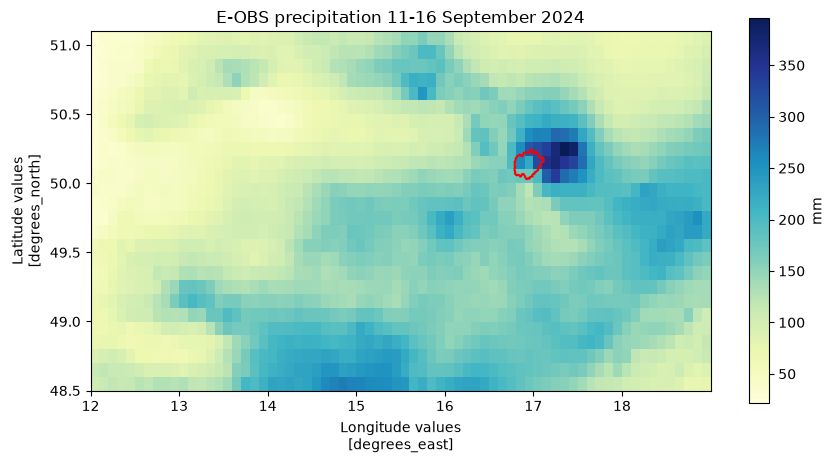

In [3]:
rr = open_eobs(RR_CZ)
boris = rr.sel(time=slice("2024-09-11", "2024-09-16")).sum("time").compute()
fig, ax = plt.subplots(figsize=(10, 5))
boris.plot(ax=ax, cmap="YlGnBu", cbar_kwargs={"label": "mm"})
catchment.boundary.plot(ax=ax, color="red")
ax.set_title("E-OBS precipitation 11-16 September 2024")
plt.show()

In [4]:
prec_eobs = eobs_catchment_series(RR_CZ, catchment, "rr")
temp_eobs = eobs_catchment_series(TG_CZ, catchment, "tg")
print("catchment precipitation 11-16 Sept 2024: %.0f mm" % prec_eobs.loc["2024-09-11":"2024-09-16"].sum())
prec_eobs.loc["2024-09-08":"2024-09-18"].round(1)

catchment precipitation 11-16 Sept 2024: 248 mm


time
2024-09-08     0.0
2024-09-09    19.3
2024-09-10     4.0
2024-09-11     3.3
2024-09-12    43.9
2024-09-13    84.9
2024-09-14    93.0
2024-09-15    20.8
2024-09-16     2.1
2024-09-17     0.0
2024-09-18     0.0
Name: rr, dtype: float64

In [5]:
lamah = load_hbv_inputs(GAUGE_ID, attrs)
overlap = slice("2011-01-01", "2017-12-31")
p_factor = linear_scaling_factors(prec_eobs[overlap], lamah["prec"][overlap], kind="ratio")
t_offset = linear_scaling_factors(temp_eobs[overlap], lamah["temp"][overlap], kind="difference")
print(pd.DataFrame({"P factor": p_factor, "T offset (degC)": t_offset}).round(2).T)

lat, _ = gauge_latlon(GAUGE_ID, attrs)
forcing = pd.DataFrame({"prec": apply_linear_scaling(prec_eobs, p_factor, "ratio"),
                        "temp": apply_linear_scaling(temp_eobs, t_offset, "difference")})
forcing["pet"] = oudin_pet(forcing["temp"], forcing.index.dayofyear, lat)
check = pd.DataFrame({"E-OBS corrected": forcing.loc["2011":"2017", ["prec", "temp"]].mean(),
                      "ERA5-Land": lamah.loc["2011":"2017", ["prec", "temp"]].mean()})
check.round(2)

                   1     2     3     4     5     6     7     8     9     10  \
P factor         1.20  1.40  1.24  1.39  1.10  1.26  1.24  1.40  1.19  1.11   
T offset (degC) -0.95 -0.69 -0.48 -0.30 -0.14  0.08  0.12  0.22  0.48  0.22   

                   11    12  
P factor         1.26  1.31  
T offset (degC) -0.22 -0.80  


,E-OBS corrected,ERA5-Land
prec,2.72,2.72
temp,6.82,6.82


simulated daily peak: 325 m3/s on 2024-09-14


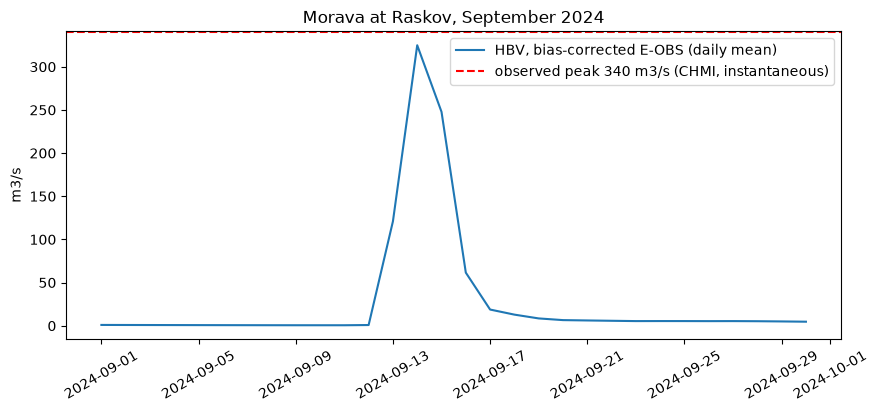

In [6]:
sim = run_hbv(forcing.loc["2022-01-01":"2024-12-31"], params, zones)
q = sim["q_sim"] * to_m3s
sept = q.loc["2024-09-01":"2024-09-30"]
peak_sim = sept.max()
print("simulated daily peak: %.0f m3/s on %s" % (peak_sim, sept.idxmax().date()))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sept, label="HBV, bias-corrected E-OBS (daily mean)")
ax.axhline(OBSERVED_PEAK_M3S, color="red", linestyle="--", label="observed peak 340 m3/s (CHMI, instantaneous)")
ax.set(ylabel="m3/s", title="Morava at Raskov, September 2024")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.show()

In [7]:
q_hist = run_hbv(lamah.loc[:"2017-12-31"], params, zones)["q_sim"] * to_m3s
gev_model = fit_gev_lmom(annual_maxima(q_hist.loc["1981-11-01":"2017-10-31"])["peak"])
t_event = return_period(gev_model, peak_sim)
rp_event = min(JRC_RETURN_PERIODS, key=lambda rp: abs(np.log(rp / t_event)))
print(f"return period of the simulated peak in the model's own climate: {t_event:.0f} years")
print(f"closest JRC map: RP{rp_event}")

return period of the simulated peak in the model's own climate: 415 years
closest JRC map: RP500


In [8]:
# Catchment 824 has no satellite footprint for Boris: no Copernicus EMS AOI covers it (EMSR756/757/759/764),
# and GFM's Sentinel-1 passes of 15, 18 and 20 Sept detect no flood pixels in it. Without the file the
# validation is skipped; drop a footprint at FOOTPRINT (e.g. for another catchment) and it runs again.
with rasterio.open(DATA_PROCESSED / "jrc" / f"jrc_rp{rp_event}_{GAUGE_ID}.tif") as src:
    model_wet = src.read(1) > 0
    shape, transform = model_wet.shape, src.transform
if FOOTPRINT.exists():
    footprint = gpd.read_file(FOOTPRINT).to_crs(4326)
    domain = catchment if AOI_FILE is None else gpd.overlay(catchment, gpd.read_file(AOI_FILE).to_crs(4326),
                                                            how="intersection")
    observed_wet = rasterize(((geom, 1) for geom in footprint.geometry), out_shape=shape,
                             transform=transform, fill=0).astype(bool)
    inside = rasterize(((geom, 1) for geom in domain.geometry), out_shape=shape,
                       transform=transform, fill=0).astype(bool)
    scores = flood_extent_scores(model_wet & inside, observed_wet & inside)
    print({name: round(float(value), 2) for name, value in scores.items()})
else:
    footprint = None
    print(f"no satellite footprint ({FOOTPRINT.name} not found): HR/FAR/CSI skipped")

no satellite footprint (observed_flood_2024.gpkg not found): HR/FAR/CSI skipped


In [9]:
buildings = gpd.read_file(DATA_PROCESSED / f"buildings_{GAUGE_ID}.gpkg")
points = buildings.copy()
points["geometry"] = buildings.to_crs(3035).representative_point().to_crs(4326)
depth = sample_depth(DATA_PROCESSED / "jrc" / f"jrc_rp{rp_event}_{GAUGE_ID}.tif", points)
if footprint is not None:
    hit = points.within(footprint.union_all()).to_numpy()
    event_depth = np.where(hit, np.where(depth > 0, depth, 0.5), 0.0)   # 0.5 m where the map is dry
    source = "the observed footprint"
else:
    hit = depth > 0                    # no observation: the map's own wet area stands in for the footprint
    event_depth = np.where(hit, depth, 0.0)
    source = f"the RP{rp_event} map's wet area (no observed footprint)"
event_loss = points["value_eur"].to_numpy() * damage_ratio(event_depth)
print(f"{int(hit.sum())} buildings inside {source}")
print(f"event loss: {event_loss.sum() / 1e6:.2f} million EUR "
      f"({int((hit & (depth == 0)).sum())} of them got the assumed 0.5 m)")

193 buildings inside the RP500 map's wet area (no observed footprint)
event loss: 7.23 million EUR (0 of them got the assumed 0.5 m)


In [10]:
rng = np.random.default_rng(0)
issue_date = pd.Timestamp("2024-09-10")
q20 = return_level(gev_model, [20])[0]
peaks = []
for member in range(50):
    f = forcing.loc["2022-01-01":"2024-09-30"].copy()
    window = (f.index >= issue_date) & (f.index < issue_date + pd.DateOffset(days=10))
    f.loc[window, "prec"] *= rng.lognormal(mean=0.0, sigma=0.3)
    peaks.append(run_hbv(f, params, zones)["q_sim"].loc[issue_date:].max() * to_m3s)
peaks = np.array(peaks)
print(f"50-member ensemble issued {issue_date.date()}: median peak {np.median(peaks):.0f} m3/s, "
      f"5-95%: {np.percentile(peaks, 5):.0f}-{np.percentile(peaks, 95):.0f} m3/s")
print(f"probability of exceeding the model's 20-year flood ({q20:.0f} m3/s): {np.mean(peaks > q20):.0%}")

50-member ensemble issued 2024-09-10: median peak 341 m3/s, 5-95%: 162-614 m3/s
probability of exceeding the model's 20-year flood (80 m3/s): 98%
